# Genómica: VCF, frecuencia y ubicación en el gen

**Responsable:** XomiDess (Integrante 2)

**Proyecto:** Caso 1 · PAH (GRCh38, NM_000277.3, NP_000268.1, PDB 6HYC)


In [1]:
# Configuración: correr esta celda primero
import os
%cd /content
if not os.path.exists("Caso_1_PHA_Humano"):
    !git clone https://github.com/XomiDessu/Caso_1_PHA_Humano.git
%cd /content/Caso_1_PHA_Humano
%pip install -q pandas numpy requests matplotlib biopython

import pandas as pd
import numpy as np

/content
Cloning into 'Caso_1_PHA_Humano'...
remote: Enumerating objects: 52, done.
remote: Counting objects: 100% (52/52), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 52 (delta 11), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (52/52), 52.93 KiB | 1.56 MiB/s, done.
Resolving deltas: 100% (11/11), done.
/content/Caso_1_PHA_Humano


In [2]:
import shutil
import os

# Ruta de la carpeta anidada que se creó por error
ruta_anidada = "/content/Caso_1_PHA_Humano/Caso_1_PHA_Humano"

if os.path.exists(ruta_anidada):
    shutil.rmtree(ruta_anidada)
    print(f"¡Limpieza completada! Se eliminó correctamente la carpeta anidada: {ruta_anidada}")
else:
    print("No se encontraron carpetas anidadas, el directorio está limpio.")

No se encontraron carpetas anidadas, el directorio está limpio.


## 1. Cargar el VCF (`database/genomic/PAH_variants_masked_GRCh38.vcf`) y separar POPAF


In [3]:
from pathlib import Path
import matplotlib.pyplot as plt

VCF_PATH = Path("database/genomic/PAH_variants_masked_GRCh38.vcf")
GTF_PATH = Path("database/genomic/PAH_NM_000277.3_GRCh38_subset.gtf")
META_PATH = Path("database/metadata/variant_metadata.tsv")
TABLA_MAESTRA_PATH = Path("resultados/tabla_maestra.tsv")
OUT_ANOTACIONES = Path("resultados/01_anotaciones_genomicas.tsv")
OUT_FIGURA = Path("resultados/figuras/01_frecuencia_y_regiones.png")

os.makedirs("resultados/figuras", exist_ok=True)
def parse_vcf(vcf_path):
  records = []
  with open(vcf_path, "r", encoding="utf-8") as f:
    for line in f:
      if line.startswith("#"):
        continue
      chrom, pos, var_id, ref, alt, qual, ftl, info = line.strip().split("\t")
      pos = int(pos)

#Extraer POPAF del campo de INFO

      info_dict = dict(item.split("=") for item in info.split(";") if "=" in item)
      popaf = float(info_dict.get("POPAF", np.nan))

#Clasificar tipo y subtipo de la variante

      len_ref, len_alt = len(ref), len(alt)
      if len_ref == 1 and len_alt == 1:
          var_type = "SNV"
          var_subtype = "transición" if {ref, alt} in [{"A", "G"}, {"C", "T"}] else "transversión"
      elif len_ref > len_alt:
          indel_len = len_ref - len_alt
          var_type = "Deleción"
          var_subtype = f"deleción de {indel_len} pb ({'in-frame' if indel_len % 3 == 0 else 'frameshift'})"
      elif len_alt > len_ref:
          indel_len = len_alt - len_ref
          var_type = "Inserción"
          var_subtype = f"inserción de {indel_len} pb"
      else:
          var_type = "MNV / Compleja"
          var_subtype = "sustitución múltiple"

#Clasificación por frecuencia poblacional

      if popaf == 0:
          af_cat = "Ausente (0)"
      elif popaf < 0.0001:
          af_cat = "Ultra-rara (<0.01%)"
      elif popaf < 0.001:
          af_cat = "Muy rara (0.01% - 0.1%)"
      elif popaf < 0.01:
          af_cat = "Rara (0.1% - 1%)"
      elif popaf < 0.05:
          af_cat = "Baja frecuencia (1% - 5%)"
      elif popaf <= 0.50:
          af_cat = "Común (5% - 50%)"
      else:
          af_cat = "Común / Alelo mayoritario (>50%)"

      records.append({
          "variant_id": var_id,
          "chrom": chrom,
          "pos": pos,
          "end_pos": pos + len_ref - 1,
          "ref": ref,
          "alt": alt,
          "genomic_location": f"{chrom}:{pos}" if len_ref == 1 else f"{chrom}:{pos}-{pos + len_ref - 1}",
          "variant_type": var_type,
          "variant_subtype": var_subtype,
          "POPAF": popaf,
          "af_category": af_cat,
          "is_major_allele": popaf > 0.5
      })
  return pd.DataFrame(records)

df_vcf = parse_vcf(VCF_PATH)

#Verificación cruzada con variant_metadata.tsv
if META_PATH.exists():
    df_meta = pd.read_csv(META_PATH, sep="\t")
    assert np.allclose(df_vcf["POPAF"], df_meta["population_AF_snapshot"], equal_nan=True), "Diferencia en POPAF respecto al metadata"
else:
    print(f"El archivo {META_PATH} no se encontró. Saltando verificación.")

display(df_vcf)

,variant_id,chrom,pos,end_pos,ref,alt,genomic_location,variant_type,variant_subtype,POPAF,af_category,is_major_allele
0,VAR001,chr12,102840437,102840437,A,G,chr12:102840437,SNV,transición,0.041240,Baja frecuencia (1% - 5%),False
1,VAR002,chr12,102840473,102840473,G,A,chr12:102840473,SNV,transición,0.007790,Rara (0.1% - 1%),False
2,VAR003,chr12,102840493,102840493,G,A,chr12:102840493,SNV,transición,0.000920,Muy rara (0.01% - 0.1%),False
3,VAR004,chr12,102843690,102843690,G,C,chr12:102843690,SNV,transversión,0.849530,Común / Alelo mayoritario (>50%),True
4,VAR005,chr12,102844388,102844388,T,G,chr12:102844388,SNV,transversión,0.000004,Ultra-rara (<0.01%),False
5,VAR006,chr12,102846901,102846901,G,A,chr12:102846901,SNV,transición,0.015820,Baja frecuencia (1% - 5%),False
6,VAR007,chr12,102852917,102852917,C,T,chr12:102852917,SNV,transición,0.000010,Ultra-rara (<0.01%),False
7,VAR008,chr12,102852922,102852922,C,T,chr12:102852922,SNV,transición,0.197820,Común (5% - 50%),False
8,VAR009,chr12,102855233,102855233,G,A,chr12:102855233,SNV,transición,0.000400,Muy rara (0.01% - 0.1%),False
9,VAR010,chr12,102877572,102877572,G,A,chr12:102877572,SNV,transición,0.230470,Común (5% - 50%),False


## 2. Cargar el GTF (`database/genomic/PAH_NM_000277.3_GRCh38_subset.gtf`)


In [4]:
def parse_gtf(gtf_path):
    records = []
    with open(gtf_path, "r", encoding="utf-8") as f:
        for line in f:
            if line.startswith("#"):
                continue

            fields = line.strip().split("\t")
            if len(fields) != 9:
                continue

            chrom, source, feature, start, end, score, strand, frame, attributes = fields

            # Procesar los atributos (que vienen en formato 'clave "valor";')
            attr_dict = {}
            for attr in attributes.split(";"):
                attr = attr.strip()
                if not attr:
                    continue
                parts = attr.split(" ")
                if len(parts) >= 2:
                    key = parts[0]
                    val = " ".join(parts[1:]).replace('"', '')
                    attr_dict[key] = val

            records.append({
                "chrom": chrom,
                "feature": feature,
                "start": int(start),
                "end": int(end),
                "strand": strand,
                "gene_id": attr_dict.get("gene_id", ""),
                "transcript_id": attr_dict.get("transcript_id", ""),
                "exon_number": attr_dict.get("exon_number", "")
            })

    return pd.DataFrame(records)

df_gtf = parse_gtf(GTF_PATH)
display(df_gtf.head(10))

,chrom,feature,start,end,strand,gene_id,transcript_id,exon_number
0,chr12,gene,102836889,102917244,-,ENSG00000171759,,
1,chr12,transcript,102836889,102917244,-,ENSG00000171759,NM_000277.3,
2,chr12,exon,102836889,102839218,-,ENSG00000171759,NM_000277.3,13
3,chr12,CDS,102839175,102839218,-,ENSG00000171759,NM_000277.3,13
4,chr12,exon,102840400,102840515,-,ENSG00000171759,NM_000277.3,12
5,chr12,CDS,102840400,102840515,-,ENSG00000171759,NM_000277.3,12
6,chr12,exon,102843646,102843779,-,ENSG00000171759,NM_000277.3,11
7,chr12,CDS,102843646,102843779,-,ENSG00000171759,NM_000277.3,11
8,chr12,exon,102844336,102844431,-,ENSG00000171759,NM_000277.3,10
9,chr12,CDS,102844336,102844431,-,ENSG00000171759,NM_000277.3,10


## 3. Tipo de variante y alelo de referencia minoritario (POPAF > 0.5)


--- Conteo por tipo de variante ---


,Cantidad
variant_type,
SNV,14
Deleción,1



--- Variantes con alelo de referencia minoritario (POPAF > 0.5): 1 ---


,variant_id,chrom,pos,ref,alt,POPAF,variant_type
3,VAR004,chr12,102843690,G,C,0.84953,SNV


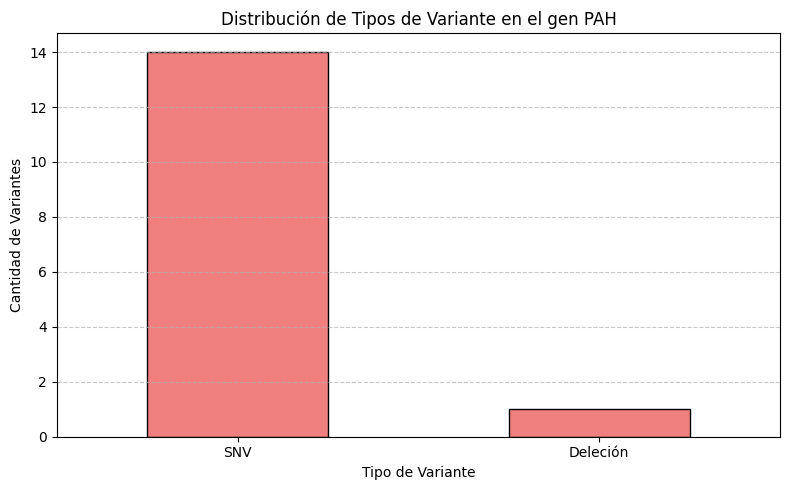

In [5]:
# Conteo de los tipos de variante
conteo_tipos = df_vcf['variant_type'].value_counts()
print("--- Conteo por tipo de variante ---")
display(conteo_tipos.to_frame(name="Cantidad"))

# Filtrar las variantes donde el alelo de referencia es el minoritario (POPAF > 0.5)
alelo_ref_minoritario = df_vcf[df_vcf['POPAF'] > 0.5]
print(f"\n--- Variantes con alelo de referencia minoritario (POPAF > 0.5): {len(alelo_ref_minoritario)} ---")
display(alelo_ref_minoritario[['variant_id', 'chrom', 'pos', 'ref', 'alt', 'POPAF', 'variant_type']])

# Gráfico de la distribución de tipos de variante
plt.figure(figsize=(8, 5))
conteo_tipos.plot(kind='bar', color='lightcoral', edgecolor='black')
plt.title("Distribución de Tipos de Variante en el gen PAH")
plt.xlabel("Tipo de Variante")
plt.ylabel("Cantidad de Variantes")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(OUT_FIGURA, dpi=300) # Guarda la imagen antes de mostrarla
plt.show()

## 4. Ubicación de cada variante: exón, CDS, UTR o intrón, y distancia al borde de exón


In [6]:
def anotar_ubicacion(pos, df_gtf):
    exones = df_gtf[df_gtf['feature'] == 'exon']
    cds = df_gtf[df_gtf['feature'] == 'CDS']

    ubicacion = "Intrón"
    distancia_borde = float('inf')

    # Calcular distancia al borde de exón más cercano y verificar si está en exón
    for _, exon in exones.iterrows():
        d_start = abs(pos - exon['start'])
        d_end = abs(pos - exon['end'])
        distancia_borde = min(distancia_borde, d_start, d_end)

        if exon['start'] <= pos <= exon['end']:
            ubicacion = "UTR"  # Asignamos UTR inicialmente si cae en exón

    # Verificar si cae dentro de un CDS
    for _, c in cds.iterrows():
        if c['start'] <= pos <= c['end']:
            ubicacion = "CDS"
            break

    return ubicacion, distancia_borde

# Aplicar la función a cada variante
resultados = df_vcf['pos'].apply(lambda x: anotar_ubicacion(x, df_gtf))
df_vcf['ubicacion'] = [res[0] for res in resultados]
df_vcf['distancia_borde_exon'] = [res[1] for res in resultados]

print("--- Anotación de Ubicación Genómica ---")
display(df_vcf[['variant_id', 'chrom', 'pos', 'ref', 'alt', 'ubicacion', 'distancia_borde_exon']])

--- Anotación de Ubicación Genómica ---


,variant_id,chrom,pos,ref,alt,ubicacion,distancia_borde_exon
0,VAR001,chr12,102840437,A,G,CDS,37
1,VAR002,chr12,102840473,G,A,CDS,42
2,VAR003,chr12,102840493,G,A,CDS,22
3,VAR004,chr12,102843690,G,C,CDS,44
4,VAR005,chr12,102844388,T,G,CDS,43
5,VAR006,chr12,102846901,G,A,CDS,6
6,VAR007,chr12,102852917,C,T,CDS,33
7,VAR008,chr12,102852922,C,T,CDS,28
8,VAR009,chr12,102855233,G,A,CDS,97
9,VAR010,chr12,102877572,G,A,Intrón,22


## 5. Guardar `resultados/anotacion_genomica.tsv`


In [7]:
# Guardar el dataframe con todas las anotaciones genómicas en un archivo TSV
df_vcf.to_csv(OUT_ANOTACIONES, sep="\t", index=False)
print(f"¡Anotaciones guardadas exitosamente en: {OUT_ANOTACIONES}!")

# Mostrar las columnas finales guardadas
print("\nColumnas del archivo generado:")
print(list(df_vcf.columns))

¡Anotaciones guardadas exitosamente en: resultados/01_anotaciones_genomicas.tsv!

Columnas del archivo generado:
['variant_id', 'chrom', 'pos', 'end_pos', 'ref', 'alt', 'genomic_location', 'variant_type', 'variant_subtype', 'POPAF', 'af_category', 'is_major_allele', 'ubicacion', 'distancia_borde_exon']


## Cierre de la sección

- **Observamos:** Un total de 15 variantes en el gen *PAH*, compuestas por 14 SNVs y 1 deleción. La gran mayoría se ubica en regiones codificantes (CDS), a excepción de una variante (VAR010) que cae en un intrón.
- **Inferimos que:** La variante VAR004 tiene una frecuencia poblacional superior al 50% (POPAF > 0.5), lo que indica que el alelo de referencia en el genoma GRCh38 es en realidad el alelo minoritario en la población general. Además, la variante intrónica (VAR010) se encuentra a 22 pares de bases del exón, lo que podría tener implicaciones en el splicing.
- **La evidencia aporta:** Una caracterización genómica detallada de las variantes, incluyendo su frecuencia poblacional, tipo de mutación y ubicación precisa en relación con la estructura del gen (exones/intrones/CDS).
- **Concluimos:** Las variantes en regiones CDS son las principales candidatas para tener un impacto en la secuencia de la proteína. VAR004 es probablemente benigna o de bajo impacto patogénico dada su altísima frecuencia poblacional.
- **Falta evidencia:** Para determinar si las variantes en CDS causan cambios de aminoácidos (sinónimas vs. missense/nonsense) y predecir su impacto patogénico o estructural. Esto se analizará en los próximos notebooks (transcrito, proteína y estructura 3D).